# 03 · Imputación escalonada (ítems D y E del artículo)

**Entrada:** `data/processed/<estación>/<estación>_horario.csv` (notebook 01).

**Salida:** `data/clean/<estación>/<estación>_horario_limpio.csv`, la serie horaria **sin huecos**, en la que cada valor lleva una **etiqueta de calidad** que dice de dónde salió.

## Qué dice el artículo

**Ítem D (nivel del agua)** — cascada de cuatro niveles; se usa el primero que funcione:

| Nivel | Cuándo | Qué se hace | Etiqueta |
|---|---|---|---|
| 1 | hay dato observado | se conserva tal cual | **REAL** |
| 2 | hueco corto con datos a ambos lados | interpolación lineal (línea recta entre los extremos) | **ALTA** |
| 3 | hueco más largo | promedio de la **misma fecha y hora** (mes-día-hora) en otros años, si hay al menos 2 valores | **MEDIA** |
| 3b | no hay datos de esa fecha en otros años | promedio de **cualquier día del mismo mes a la misma hora** en otros años | **MEDIA** |
| — | nada de lo anterior funciona | spline cúbico como último recurso | **BAJA** |
| 4 | ni siquiera el spline (p. ej. hueco al inicio de la serie) | queda vacío | **SIN_DATO** |

Además cada variable lleva columnas de **trazabilidad**: valor original, valor final, bandera de imputación (0/1) y etiqueta de calidad.

**Ítem E (resto de variables)** — se aplica la misma cascada a las demás variables, con un ajuste: **la lluvia nunca se interpola** (si un hueco está entre una hora seca y una lluviosa, la línea recta inventaría lluvia que no ocurrió). Para la lluvia solo se usan el promedio histórico de calendario o la etiqueta sin dato.

## Qué se adapta y por qué

El artículo trabaja a 5 minutos; aquí la serie es horaria. Antes de fijar hasta qué largo de hueco conviene la interpolación lineal, se **prueba con los propios datos** (sección 2): se borran a propósito tramos que sí tienen dato, se rellenan con cada método y se mide el error. Esa prueba define un umbral **por variable**, que es lo que el ítem E llama "ajustes específicos por variable".

## 0. Librerías y parámetros

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import CubicSpline

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = RAIZ / "data" / "processed"
CLEAN = RAIZ / "data" / "clean"

ESTACIONES = ["La_Lindosa", "Los_Micos"]
VARIABLES = ["nivel_m", "temperatura_c", "lluvia_mm"]

LIMITE_CORTO_H = 6     # mismas categorías que el notebook 02
LIMITE_MEDIO_H = 24
MIN_VALORES_HISTORICOS = 2   # el artículo exige al menos 2 valores históricos para promediar

CALIDADES = ["REAL", "ALTA", "MEDIA", "BAJA", "SIN_DATO"]
COLOR_CALIDAD = {"REAL": "#1d3557", "ALTA": "#2a9d8f", "MEDIA": "#e9c46a", "BAJA": "#e76f51", "SIN_DATO": "#adb5bd"}

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", "{:,.3f}".format)

horario = {}
for est in ESTACIONES:
    horario[est] = pd.read_csv(PROCESSED / est / f"{est}_horario.csv",
                               parse_dates=["fecha_hora"], index_col="fecha_hora")
    print(f"{est}: {len(horario[est]):,} horas")

La_Lindosa: 74,726 horas
Los_Micos: 74,716 horas


## 1. Las piezas de la cascada

Se escriben como funciones pequeñas para poder probarlas por separado.

### 1.1 Promedio histórico de calendario (niveles 3 y 3b)

- **Nivel 3:** para una hora vacía, por ejemplo el 15 de marzo de 2020 a las 14:00, se promedian los valores **observados** del 15 de marzo a las 14:00 de todos los demás años. Como el valor de 2020 está vacío, el promedio de todos los años con dato ya excluye 2020 automáticamente.
- **Nivel 3b:** si no hay al menos 2 valores para esa fecha exacta, se promedian todas las horas 14:00 de **marzo** de los **otros** años (aquí sí hay que quitar a mano el mismo año, porque marzo de 2020 puede tener otros días con dato).

Solo se usan valores **REAL** para calcular los promedios, nunca valores ya imputados.

In [2]:
def promedio_mismo_dia(observado, objetivo_idx):
    """Nivel 3: promedio de la misma fecha (mes-día) y hora en otros años."""
    obs = observado.dropna()
    clave = [obs.index.month, obs.index.day, obs.index.hour]
    tabla = obs.groupby(clave).agg(["mean", "count"])
    claves_obj = pd.MultiIndex.from_arrays([objetivo_idx.month, objetivo_idx.day, objetivo_idx.hour])
    t = tabla.reindex(claves_obj)
    valor = t["mean"].where(t["count"] >= MIN_VALORES_HISTORICOS)
    return pd.Series(valor.values, index=objetivo_idx)

def promedio_mismo_mes(observado, objetivo_idx):
    """Nivel 3b: promedio de cualquier día del mismo mes, a la misma hora, en OTROS años."""
    obs = observado.dropna()
    por_anio = obs.groupby([obs.index.year, obs.index.month, obs.index.hour]).agg(["sum", "count"])
    total = por_anio.groupby(level=[1, 2]).sum()
    k_total = pd.MultiIndex.from_arrays([objetivo_idx.month, objetivo_idx.hour])
    k_anio = pd.MultiIndex.from_arrays([objetivo_idx.year, objetivo_idx.month, objetivo_idx.hour])
    tot = total.reindex(k_total)
    propio = por_anio.reindex(k_anio).fillna(0)          # lo del mismo año se resta
    suma = tot["sum"].values - propio["sum"].values
    conteo = tot["count"].values - propio["count"].values
    with np.errstate(invalid="ignore", divide="ignore"):
        valor = np.where(conteo >= MIN_VALORES_HISTORICOS, suma / conteo, np.nan)
    return pd.Series(valor, index=objetivo_idx)

### 1.2 Largo del hueco al que pertenece cada hora

Para decidir el método hace falta saber, para cada hora vacía, cuántas horas tiene el hueco completo.

In [3]:
def largo_del_hueco(serie):
    vacio = serie.isna()
    id_tramo = (vacio != vacio.shift()).cumsum()
    largo = vacio.groupby(id_tramo).transform("sum")
    return largo.where(vacio, 0).astype(int)

def categoria_hueco(largo):
    return pd.cut(largo, [0, LIMITE_CORTO_H, LIMITE_MEDIO_H, np.inf],
                  labels=["corto", "medio", "largo"]).astype(object).where(largo > 0, "")

## 2. ¿Hasta qué largo de hueco conviene interpolar? Prueba con los datos

Idea: tomar tramos donde **sí hay dato**, borrarlos a propósito, rellenarlos con (a) interpolación lineal y (b) promedio histórico de la misma fecha, y comparar con el valor real. Se repite 300 veces para cada largo de hueco (1, 3, 6, 12, 24, 48 y 72 h) y se calcula el **error absoluto medio (MAE)**.

Para que la prueba sea justa, el promedio histórico se calcula **sin el año del tramo borrado** (como pasaría con un hueco de verdad).

In [4]:
LARGOS_PRUEBA = [1, 3, 6, 12, 24, 48, 72]
REPETICIONES = 300
rng = np.random.default_rng(42)  # semilla fija: la prueba da siempre el mismo resultado

def prueba_huecos_artificiales(serie):
    obs = serie.dropna()
    tabla = obs.groupby([obs.index.month, obs.index.day, obs.index.hour]).agg(["sum", "count"])
    valores = serie.values
    filas = []
    for L in LARGOS_PRUEBA:
        err_lin, err_cal = [], []
        while len(err_lin) < REPETICIONES:
            i = rng.integers(1, len(serie) - L - 1)
            tramo = valores[i - 1:i + L + 1]
            if np.isnan(tramo).any():
                continue  # solo tramos completos (con dato en los extremos y en el medio)
            verdad = tramo[1:-1]
            lineal = np.linspace(tramo[0], tramo[-1], L + 2)[1:-1]
            idx = serie.index[i:i + L]
            t = tabla.reindex(pd.MultiIndex.from_arrays([idx.month, idx.day, idx.hour]))
            n = t["count"].values - 1
            calendario = np.where(n >= MIN_VALORES_HISTORICOS, (t["sum"].values - verdad) / np.maximum(n, 1), np.nan)
            if np.isnan(calendario).any():
                continue  # solo tramos donde ambos métodos pueden dar un valor
            err_lin.append(np.mean(np.abs(lineal - verdad)))
            err_cal.append(np.nanmean(np.abs(calendario - verdad)))
        filas.append({"largo del hueco (h)": L, "MAE interpolación lineal": np.mean(err_lin),
                      "MAE promedio histórico": np.mean(err_cal)})
    return pd.DataFrame(filas).set_index("largo del hueco (h)")

resultados_prueba = {}
for est in ESTACIONES:
    for var in ["nivel_m", "temperatura_c"]:
        resultados_prueba[(est, var)] = prueba_huecos_artificiales(horario[est][var])

pd.concat(resultados_prueba, axis=1).round(3)

La_Lindosa                         \
                                     nivel_m                          
                    MAE interpolación lineal MAE promedio histórico   
largo del hueco (h)                                                   
1                                      0.006                  0.128   
3                                      0.009                  0.127   
6                                      0.013                  0.125   
12                                     0.022                  0.134   
24                                     0.031                  0.128   
48                                     0.032                  0.116   
72                                     0.042                  0.125   

                                                                     \
                               temperatura_c                          
                    MAE interpolación lineal MAE promedio histórico   
largo del hueco (h)                                                   
1                                      0.390                  1.718   
3                                      0.688                  1.827   
6                                      1.237                  1.672   
12                                     2.262                  1.713   
24                                     3.598                  1.760   
48                                     3.731                  1.676   
72                                     3.718                  1.830   

                                   Los_Micos                         \
                                     nivel_m                          
                    MAE interpolación lineal MAE promedio histórico   
largo del hueco (h)                                                   
1                                      0.005                  0.116   
3                                      0.007                  0.123   
6                                      0.015                  0.132   
12                                     0.018                  0.113   
24                                     0.022                  0.108   
48                                     0.028                  0.117   
72                                     0.030                  0.119   

                                                                     
                               temperatura_c                         
                    MAE interpolación lineal MAE promedio histórico  
largo del hueco (h)                                                  
1                                      0.435                  1.491  
3                                      0.778                  1.648  
6                                      1.413                  1.512  
12                                     2.843                  1.574  
24                                     4.089                  1.617  
48                                     4.205                  1.525  
72                                     4.199                  1.526

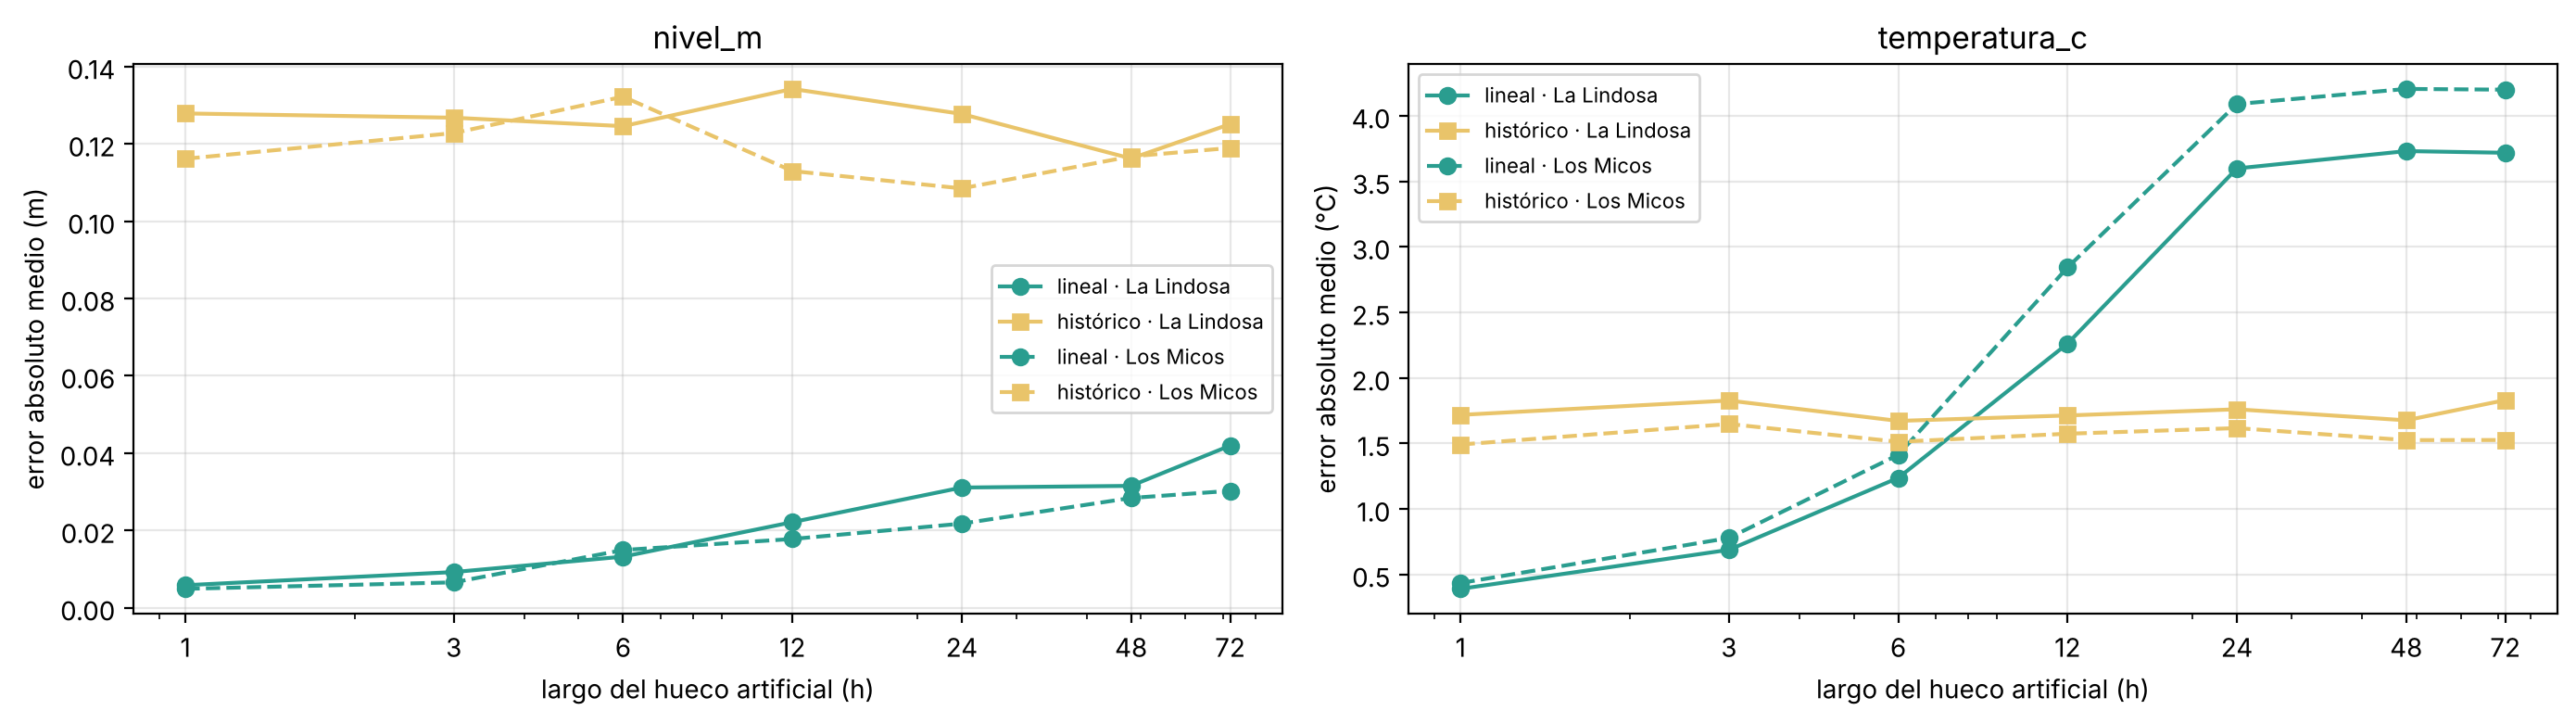

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
unidades = {"nivel_m": "m", "temperatura_c": "°C"}
for ax, var in zip(axes, ["nivel_m", "temperatura_c"]):
    for est, estilo in zip(ESTACIONES, ["-", "--"]):
        r = resultados_prueba[(est, var)]
        ax.plot(r.index, r["MAE interpolación lineal"], estilo, marker="o", color="#2a9d8f",
                label=f"lineal · {est.replace('_', ' ')}")
        ax.plot(r.index, r["MAE promedio histórico"], estilo, marker="s", color="#e9c46a",
                label=f"histórico · {est.replace('_', ' ')}")
    ax.set_xscale("log")
    ax.set_xticks(LARGOS_PRUEBA, LARGOS_PRUEBA)
    ax.set_xlabel("largo del hueco artificial (h)")
    ax.set_ylabel(f"error absoluto medio ({unidades[var]})")
    ax.set_title(var)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Lectura de la prueba y decisión

- **Nivel:** la interpolación lineal se equivoca en promedio entre 0,5 y 3 cm incluso con huecos de 24-72 h, mientras que el promedio histórico se equivoca unos **12 cm** sin importar el largo. La razón es que el nivel cambia mucho de un año a otro (en Los Micos la mediana bajó de ~0,45 a ~0,2 m en 2021-2022), así que "lo que pasó otros años" es mala guía para un año concreto. Aplicar el promedio histórico a huecos de 6-24 h, como haría el artículo con sus huecos "medios", **empeoraría** la serie. Por eso, para el nivel se interpola linealmente hasta **24 h** (huecos cortos y medios) y el promedio histórico se reserva para los huecos **largos**.
- **Temperatura:** la interpolación gana solo hasta unas **6 h**. Con huecos más largos la línea recta borra el ciclo día-noche, y el promedio histórico (que sí conserva ese ciclo) es mejor. Para la temperatura se interpola hasta 6 h (huecos cortos).
- **Lluvia:** no se interpola nunca (regla del ítem E).

**Limitación importante:** la prueba mide el error promedio. Si una crecida ocurre **completa dentro** de un hueco, ningún método la va a recuperar: la interpolación dibuja una línea entre antes y después, y el promedio histórico da un valor típico. Por eso cada valor lleva su etiqueta y se recomienda no usar valores MEDIA/BAJA para entrenar.

In [6]:
UMBRAL_LINEAL_H = {
    "nivel_m": LIMITE_MEDIO_H,        # 24 h: huecos cortos y medios
    "temperatura_c": LIMITE_CORTO_H,  # 6 h: solo huecos cortos
    "lluvia_mm": 0,                   # la lluvia no se interpola (ítem E)
}
USAR_SPLINE = {"nivel_m": True, "temperatura_c": True, "lluvia_mm": False}

## 3. La cascada completa

La función `imputar` aplica los niveles en orden. En cada paso solo se tocan las horas que siguen vacías, así un valor nunca se sobrescribe con un método de menor confianza.

In [7]:
def imputar(serie, umbral_lineal_h, usar_spline):
    original = serie.copy()
    final = serie.copy()
    calidad = pd.Series(np.where(original.notna(), "REAL", "SIN_DATO"), index=serie.index, dtype=object)
    largo = largo_del_hueco(original)

    # Nivel 2: interpolación lineal en huecos de hasta `umbral_lineal_h` horas con dato a ambos lados
    if umbral_lineal_h > 0:
        lineal = original.interpolate(method="time", limit_area="inside")
        usar = original.isna() & (largo <= umbral_lineal_h) & lineal.notna()
        final[usar] = lineal[usar]
        calidad[usar] = "ALTA"

    # Nivel 3: promedio de la misma fecha y hora en otros años
    pendientes = final.index[final.isna()]
    if len(pendientes):
        v = promedio_mismo_dia(original, pendientes).dropna()
        final[v.index] = v
        calidad[v.index] = "MEDIA"

    # Nivel 3b: promedio del mismo mes y hora en otros años
    pendientes = final.index[final.isna()]
    if len(pendientes):
        v = promedio_mismo_mes(original, pendientes).dropna()
        final[v.index] = v
        calidad[v.index] = "MEDIA"

    # Último recurso: spline cúbico ajustado a los valores observados (solo entre el primer y último dato)
    pendientes = final.index[final.isna()]
    if usar_spline and len(pendientes):
        obs = original.dropna()
        x = obs.index.asi8 / 3.6e12  # horas
        spline = CubicSpline(x, obs.values)
        dentro = pendientes[(pendientes > obs.index.min()) & (pendientes < obs.index.max())]
        if len(dentro):
            final[dentro] = spline(dentro.asi8 / 3.6e12)
            calidad[dentro] = "BAJA"

    # Nivel 4: lo que siga vacío queda como SIN_DATO
    return pd.DataFrame({
        "final": final,
        "original": original,
        "imputado": (calidad.isin(["ALTA", "MEDIA", "BAJA"])).astype(int),
        "calidad": calidad,
        "hueco": categoria_hueco(largo),
    })

## 4. Aplicar a las dos estaciones

Se imputan las tres variables de cada estación y se arma la tabla final con las columnas de trazabilidad.

In [8]:
DECIMALES = {"nivel_m": 3, "temperatura_c": 2, "lluvia_mm": 2}
limpio = {}
for est in ESTACIONES:
    h = horario[est]
    partes = [h[["fuente", "nivel_pegado"]]]
    for var in VARIABLES:
        r = imputar(h[var], UMBRAL_LINEAL_H[var], USAR_SPLINE[var])
        r["final"] = r["final"].round(DECIMALES[var])
        r.columns = [var, f"{var}_original", f"{var}_imputado", f"{var}_calidad", f"{var}_hueco"]
        partes.append(r)
    limpio[est] = pd.concat(partes, axis=1)
    print(f"{est}: listo ({len(limpio[est]):,} horas)")

# Vista de un hueco de nivel rellenado, con sus columnas de trazabilidad
df = limpio["La_Lindosa"]
primera_alta = df.index[(df.nivel_m_calidad == "ALTA") & (df.index.year >= 2021)][0]
df.loc[primera_alta - pd.Timedelta(hours=2): primera_alta + pd.Timedelta(hours=9),
       ["nivel_m", "nivel_m_original", "nivel_m_imputado", "nivel_m_calidad", "nivel_m_hueco", "fuente"]]

La_Lindosa: listo (74,726 horas)
Los_Micos: listo (74,716 horas)


,nivel_m,nivel_m_original,nivel_m_imputado,nivel_m_calidad,nivel_m_hueco,fuente
fecha_hora,,,,,,
2021-02-11 12:00:00,0.891,0.891,0,REAL,,MeerKAD
2021-02-11 13:00:00,0.878,0.878,0,REAL,,MeerKAD
2021-02-11 14:00:00,0.869,NaN,1,ALTA,corto,MeerKAD
2021-02-11 15:00:00,0.861,0.861,0,REAL,,MeerKAD
2021-02-11 16:00:00,0.854,0.854,0,REAL,,MeerKAD
2021-02-11 17:00:00,0.850,0.850,0,REAL,,MeerKAD
2021-02-11 18:00:00,0.848,0.848,0,REAL,,MeerKAD
2021-02-11 19:00:00,0.849,0.849,0,REAL,,MeerKAD
2021-02-11 20:00:00,0.846,0.846,0,REAL,,MeerKAD


## 5. Distribución de calidad

Equivalente a la Tabla VII del artículo, pero para las tres variables. Porcentaje de horas de la serie con cada etiqueta:

In [9]:
filas = []
for est, df in limpio.items():
    for var in VARIABLES:
        dist = df[f"{var}_calidad"].value_counts(normalize=True).mul(100).reindex(CALIDADES).fillna(0)
        filas.append({"estación": est, "variable": var, **dist.round(1).to_dict()})
tabla_calidad = pd.DataFrame(filas)
tabla_calidad

,estación,variable,REAL,ALTA,MEDIA,BAJA,SIN_DATO
0,La_Lindosa,nivel_m,93.000,1.100,5.900,0.000,0.000
1,La_Lindosa,temperatura_c,86.900,0.100,13.100,0.000,0.000
2,La_Lindosa,lluvia_mm,94.500,0.000,5.500,0.000,0.000
3,Los_Micos,nivel_m,90.000,2.600,7.400,0.000,0.000
4,Los_Micos,temperatura_c,92.500,0.200,7.300,0.000,0.000
5,Los_Micos,lluvia_mm,91.700,0.000,8.300,0.000,0.000


Para el **nivel**, la proporción de valores REAL + ALTA (los más confiables) es la que importa para entrenar modelos:

In [10]:
for est, df in limpio.items():
    c = df.nivel_m_calidad.value_counts(normalize=True).mul(100)
    print(f"{est}: REAL {c.get('REAL', 0):.1f} % + ALTA {c.get('ALTA', 0):.1f} % = "
          f"{c.get('REAL', 0) + c.get('ALTA', 0):.1f} % confiable; MEDIA {c.get('MEDIA', 0):.1f} %; "
          f"BAJA {c.get('BAJA', 0):.1f} %; SIN_DATO {c.get('SIN_DATO', 0):.1f} %")

La_Lindosa: REAL 93.0 % + ALTA 1.1 % = 94.1 % confiable; MEDIA 5.9 %; BAJA 0.0 %; SIN_DATO 0.0 %
Los_Micos: REAL 90.0 % + ALTA 2.6 % = 92.6 % confiable; MEDIA 7.4 %; BAJA 0.0 %; SIN_DATO 0.0 %


Por año (nivel):

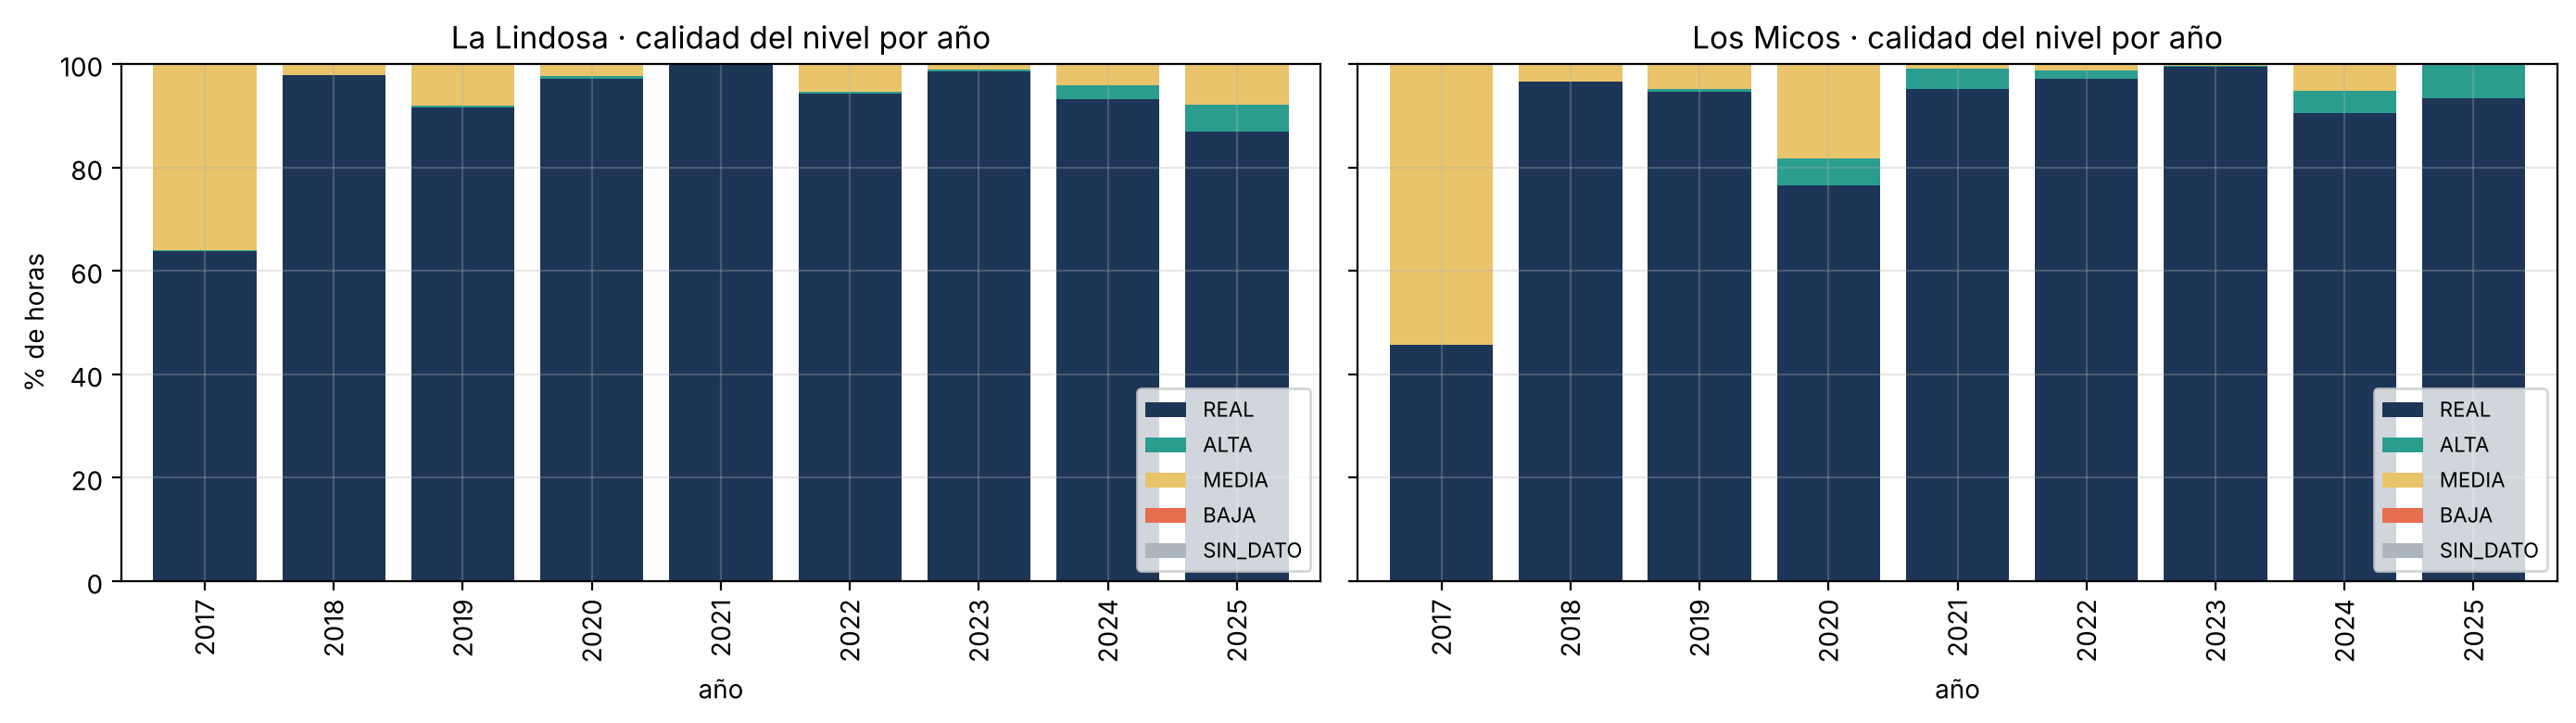

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (est, df) in zip(axes, limpio.items()):
    dist = (df.groupby(df.index.year).nivel_m_calidad.value_counts(normalize=True)
            .unstack().reindex(columns=CALIDADES).fillna(0).mul(100))
    dist.plot(kind="bar", stacked=True, ax=ax, color=[COLOR_CALIDAD[c] for c in CALIDADES], width=0.8)
    ax.set_title(f"{est.replace('_', ' ')} · calidad del nivel por año")
    ax.set_xlabel("año")
    ax.legend(loc="lower right", fontsize=8)
axes[0].set_ylabel("% de horas")
plt.tight_layout()
plt.show()

## 6. Ejemplos visuales

### 6.1 Hueco medio de nivel rellenado por interpolación (ALTA)

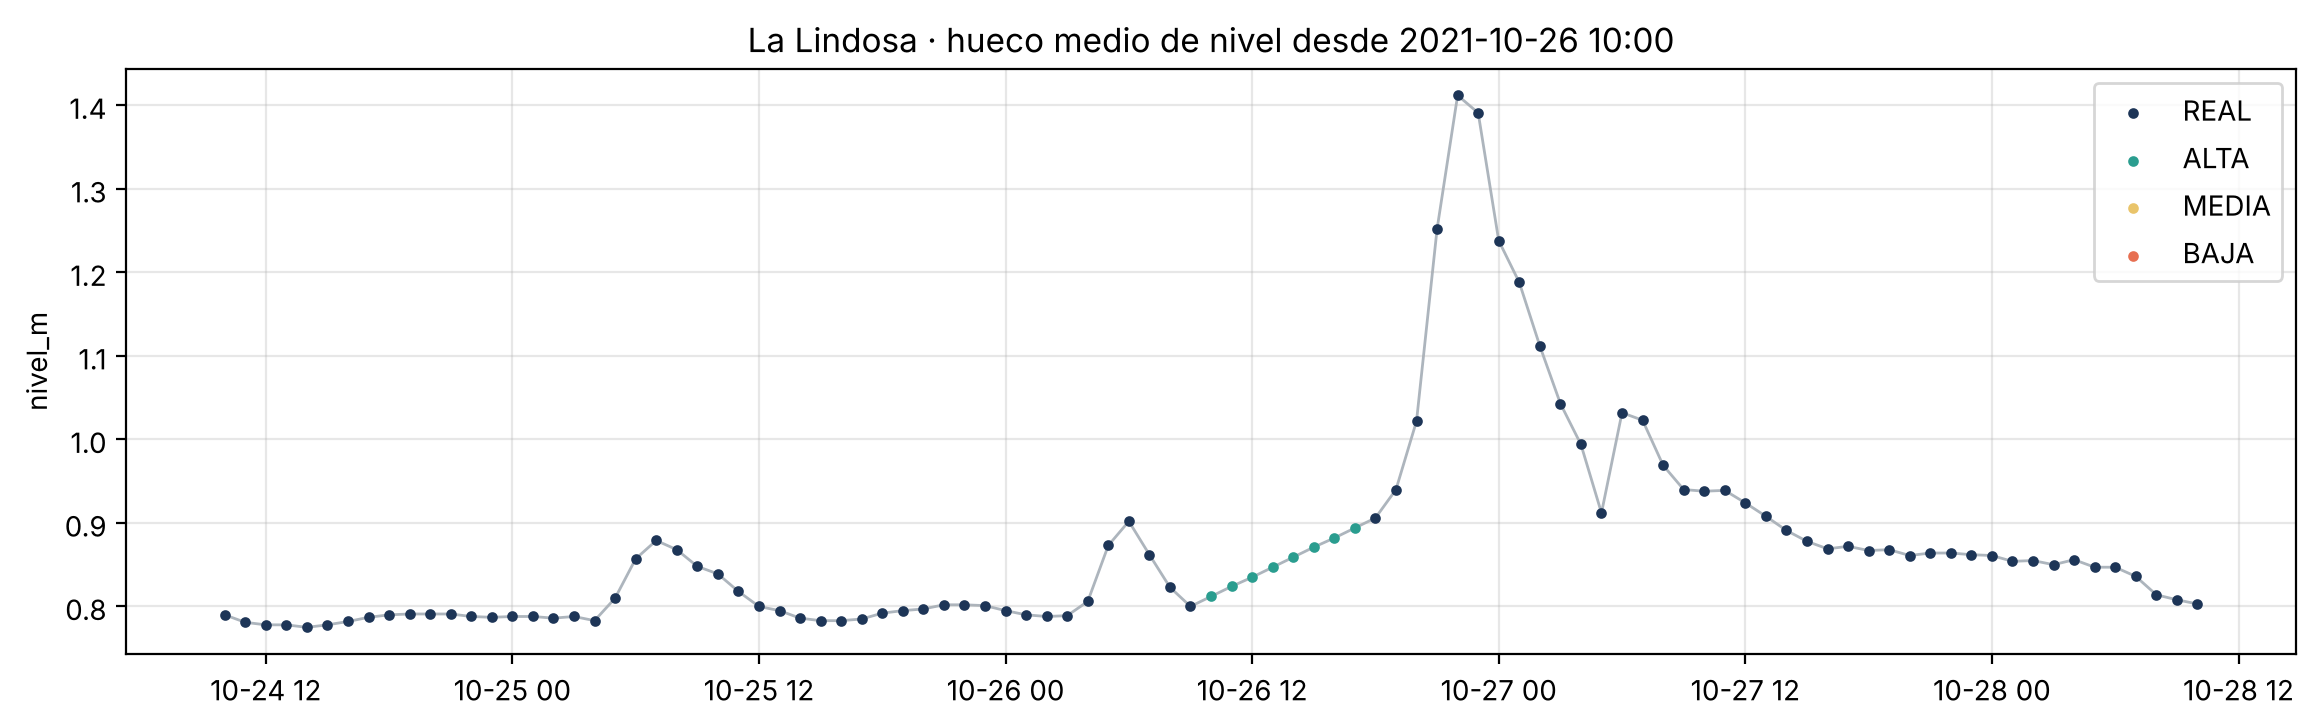

In [12]:
def graficar(est, var, inicio, fin, titulo):
    df = limpio[est].loc[inicio:fin]
    fig, ax = plt.subplots(figsize=(14, 3.8))
    ax.plot(df.index, df[var], color="#adb5bd", lw=1, zorder=1)
    for cal in CALIDADES[:-1]:
        m = df[f"{var}_calidad"] == cal
        ax.scatter(df.index[m], df.loc[m, var], s=8, color=COLOR_CALIDAD[cal], label=cal, zorder=2)
    ax.set_title(titulo)
    ax.set_ylabel(var)
    ax.legend()
    plt.show()

df = limpio["La_Lindosa"]
ejemplo = df[(df.nivel_m_hueco == "medio") & (df.index.year >= 2021)].index[0]
graficar("La_Lindosa", "nivel_m", ejemplo - pd.Timedelta(days=2), ejemplo + pd.Timedelta(days=2),
         f"La Lindosa · hueco medio de nivel desde {ejemplo:%Y-%m-%d %H:%M}")

### 6.2 Hueco largo de nivel rellenado con el promedio histórico (MEDIA)

Enero-febrero de 2020 en Los Micos (cambio de sistema MAIGRAI → MeerKAD). El relleno sigue un comportamiento "típico" de esas fechas, pero no necesariamente lo que pasó ese año: por eso su etiqueta es MEDIA. Nótese el salto en los bordes del hueco, otra razón para no usar estos tramos en el entrenamiento.

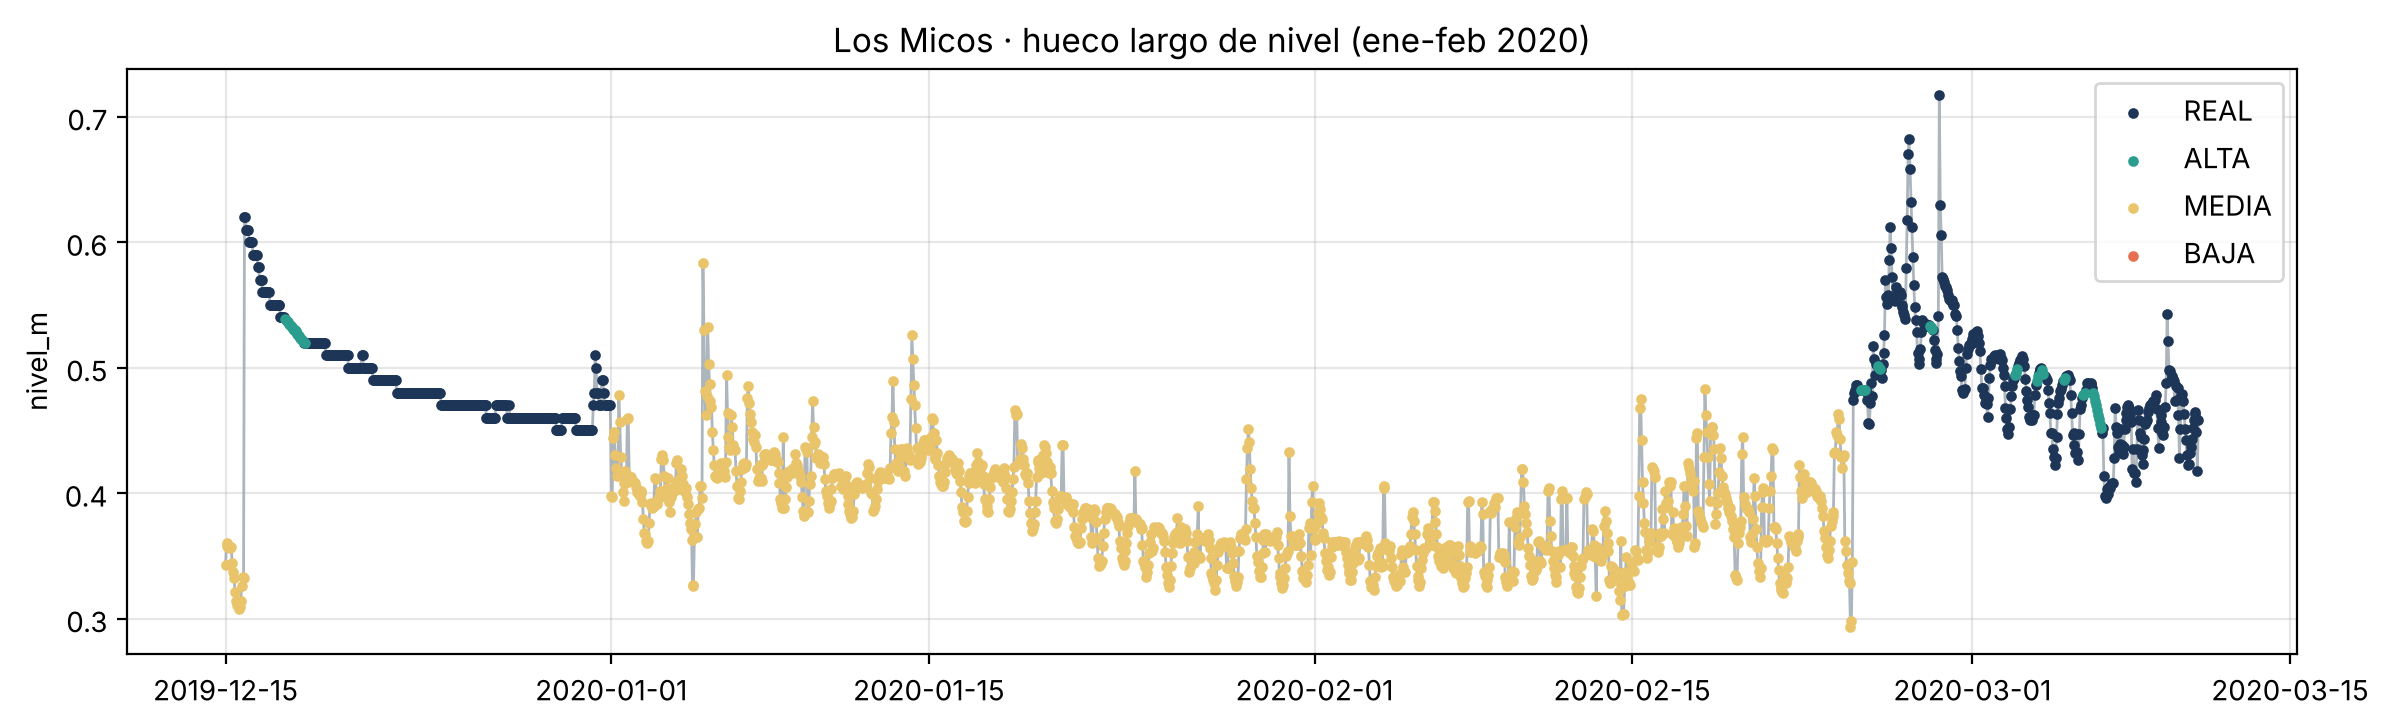

In [13]:
graficar("Los_Micos", "nivel_m", "2019-12-15", "2020-03-10", "Los Micos · hueco largo de nivel (ene-feb 2020)")

### 6.3 Temperatura: hueco largo con promedio histórico

Aquí el promedio histórico sí reproduce bien el ciclo día-noche, que la interpolación lineal habría borrado.

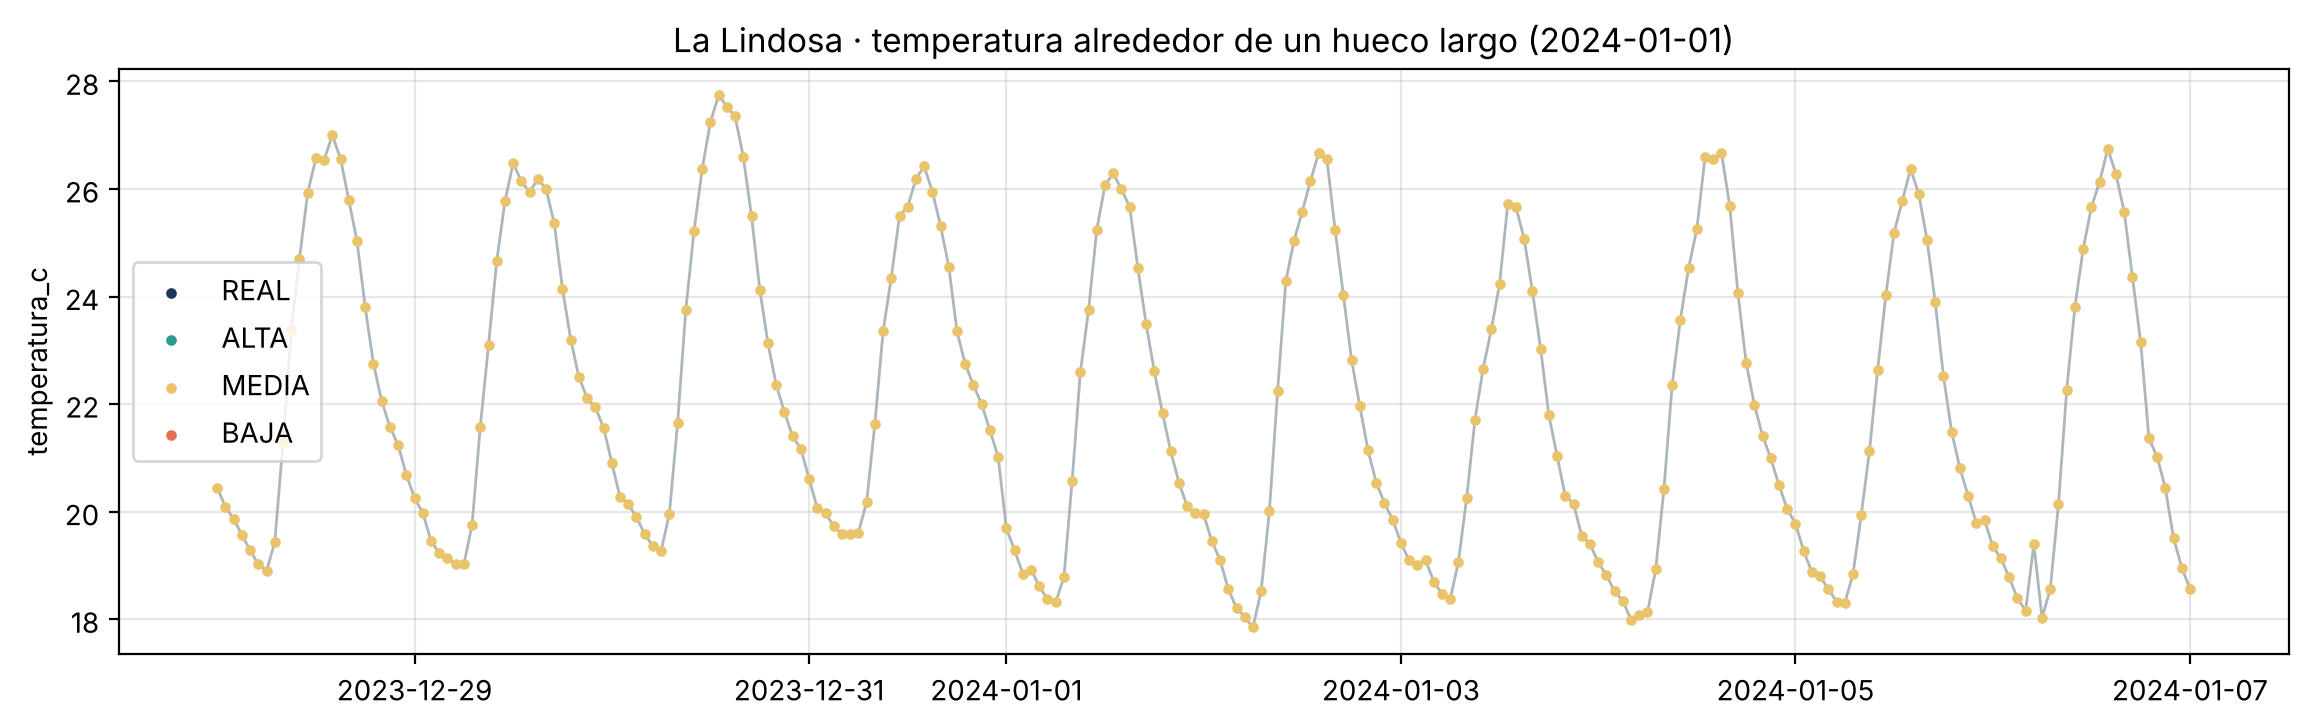

In [14]:
df = limpio["La_Lindosa"]
ejemplo = df[(df.temperatura_c_hueco == "largo") & (df.index.year == 2024)].index[0]
graficar("La_Lindosa", "temperatura_c", ejemplo - pd.Timedelta(days=4), ejemplo + pd.Timedelta(days=6),
         f"La Lindosa · temperatura alrededor de un hueco largo ({ejemplo:%Y-%m-%d})")

## 7. Controles finales

Se verifica que: (a) no queden huecos, (b) los valores imputados estén dentro de rangos físicos, (c) los valores REAL no hayan cambiado.

In [15]:
for est, df in limpio.items():
    print(f"--- {est}")
    for var in VARIABLES:
        vacios = df[var].isna().sum()
        real = df[f"{var}_calidad"] == "REAL"
        intactos = np.allclose(df.loc[real, var], df.loc[real, f"{var}_original"].round(DECIMALES[var]))
        print(f"{var:14s} vacíos: {vacios:5d} | mín {df[var].min():7.3f} | máx {df[var].max():7.3f} | "
              f"REAL intactos: {intactos}")

--- La_Lindosa
nivel_m        vacíos:     0 | mín   0.385 | máx   3.114 | REAL intactos: True
temperatura_c  vacíos:     0 | mín  10.040 | máx  34.420 | REAL intactos: True
lluvia_mm      vacíos:     0 | mín   0.000 | máx  52.000 | REAL intactos: True
--- Los_Micos
nivel_m        vacíos:     0 | mín   0.050 | máx   1.820 | REAL intactos: True
temperatura_c  vacíos:     0 | mín  13.320 | máx  38.180 | REAL intactos: True
lluvia_mm      vacíos:     0 | mín   0.000 | máx  54.500 | REAL intactos: True


Si queda alguna hora vacía (SIN_DATO) es porque está al principio de la serie, antes del primer dato de esa variable, y no hay forma razonable de rellenarla.

## 8. Guardar las series limpias

Columnas del archivo (para cada variable `X` = `nivel_m`, `temperatura_c`, `lluvia_mm`):

| Columna | Contenido |
|---|---|
| `X` | valor final, ya imputado (el que se usa para modelar) |
| `X_original` | valor observado antes de imputar (vacío si no había) |
| `X_imputado` | 1 si el valor final fue imputado, 0 si es observado |
| `X_calidad` | REAL / ALTA / MEDIA / BAJA / SIN_DATO |
| `X_hueco` | categoría del hueco al que pertenecía la hora: corto / medio / largo (vacío si era REAL) |

Más `fuente` (MAIGRAI, MeerKAD, sin_registro) y `nivel_pegado` (True si el nivel original se anuló por sensor pegado en el notebook 01).

In [16]:
orden_columnas = ["fecha_hora"] + [c for var in VARIABLES for c in
                                   [var, f"{var}_original", f"{var}_imputado", f"{var}_calidad", f"{var}_hueco"]] \
                 + ["fuente", "nivel_pegado"]
for est, df in limpio.items():
    salida = df.reset_index()
    salida["fecha_hora"] = salida.fecha_hora.dt.strftime("%Y-%m-%d %H:%M")
    ruta = CLEAN / est / f"{est}_horario_limpio.csv"
    ruta.parent.mkdir(parents=True, exist_ok=True)
    salida[orden_columnas].to_csv(ruta, index=False)
    print(f"Guardado {ruta.relative_to(RAIZ)} ({len(salida):,} filas)")

Guardado data/clean/La_Lindosa/La_Lindosa_horario_limpio.csv (74,726 filas)


Guardado data/clean/Los_Micos/Los_Micos_horario_limpio.csv (74,716 filas)


**Recomendación de uso (igual que el artículo):** para entrenar y validar modelos de predicción, usar ventanas donde el nivel sea **REAL o ALTA**; usar MEDIA/BAJA solo para análisis exploratorios o de sensibilidad. La columna `nivel_m_calidad` permite filtrar eso con una línea de código:

```python
df = pd.read_csv("data/clean/La_Lindosa/La_Lindosa_horario_limpio.csv", parse_dates=["fecha_hora"])
confiable = df[df.nivel_m_calidad.isin(["REAL", "ALTA"])]
```